In [1]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import os
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import plotly.express as px
from datetime import datetime
import ast

sys.path.append("..")

# Get data

In [105]:
path = Path(r"..\data\features\features_band_seq1.csv")
raw_features = pd.read_csv(path)
raw_features["sampled_at"] = pd.to_datetime(raw_features["sampled_at"])
raw_features = raw_features.loc[
    raw_features["sampled_at"] > datetime(2023, 1, 16)
].reset_index(drop=True)
raw_features["rms_per_band"] = raw_features["rms_per_band"].apply(ast.literal_eval)
raw_features = pd.concat(
    (raw_features, pd.json_normalize(raw_features["rms_per_band"])), axis=1
)

features = list(raw_features["rms_per_band"].iloc[0].keys())
raw_features = raw_features.sort_values("sampled_at").reset_index(drop=True)

In [106]:
raw_features["ind"] = (
    raw_features["sampled_at"].astype(str) + "_" + raw_features["cable"]
)

In [107]:
def get_l2_norm(x: pd.DataFrame):
    return np.sqrt(np.sum(np.square(x), axis=0))

In [108]:
combined_features = (
    raw_features[["ind"] + features]
    .groupby("ind")[features]
    .apply(lambda x: get_l2_norm(x))
)

In [ ]:
combined_features["cable"] = combined_features.merge(
    raw_features[["ind", "cable"]].groupby("ind")["cable"].max().reset_index(),
    left_on="ind",
    right_on="ind",
)["cable"].to_list()

combined_features["tension"] = combined_features.merge(
    raw_features[["ind", "tension"]].groupby("ind")["tension"].mean().reset_index(),
    left_on="ind",
    right_on="ind",
)["tension"].to_list()

# Fit model

In [110]:
healthy_date_limit = datetime(2023, 1, 26)

In [111]:
CABLES = ["c1", "c2", "c3", "c4"]
AXES = ["x", "y", "z"]

## One model per cable

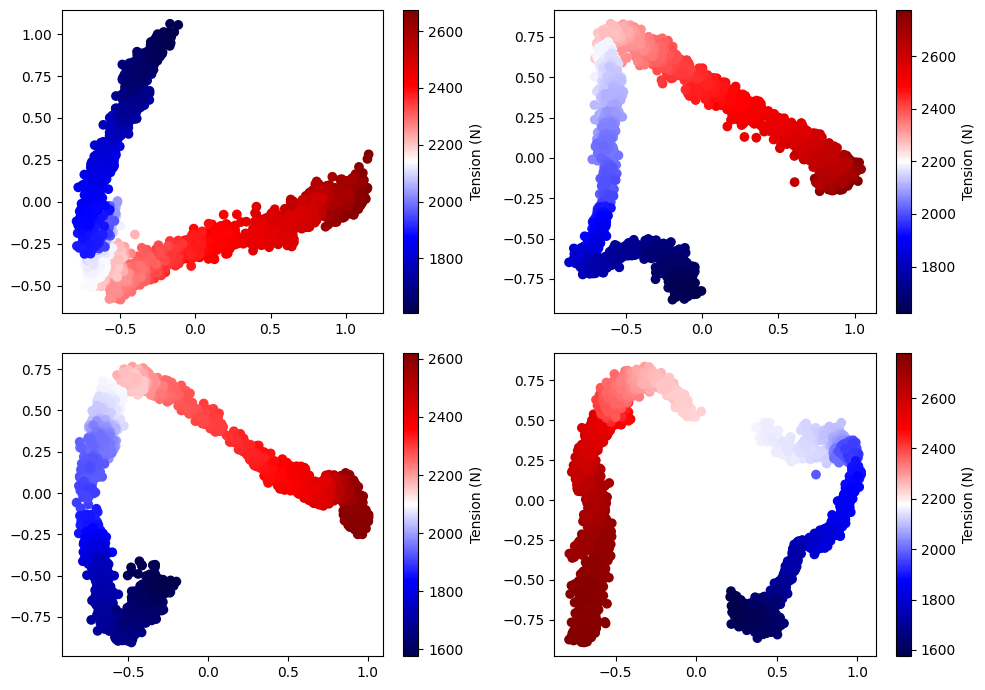

In [119]:
models = {}
results = {}
data = {}

plt.figure(figsize=(10, 7))
for i, cable in enumerate(CABLES):
    selected = combined_features.loc[combined_features["cable"]==cable].copy()
    x = selected[features].to_numpy()

    # Row-normalize
    x = x / x.sum(axis=1, keepdims=True)

    # Fit and transform
    pipe = Pipeline([("scale", MinMaxScaler()), ("pca", PCA(n_components=2))])
    pipe.fit(x)
    res = pipe.transform(x)

    # Plot
    plt.subplot(2,2,i+1)
    plt.scatter(res[:, 0], res[:, 1], c=selected["tension"], cmap="seismic")
    plt.colorbar(label="Tension (N)")
plt.tight_layout()

## One model for all cables

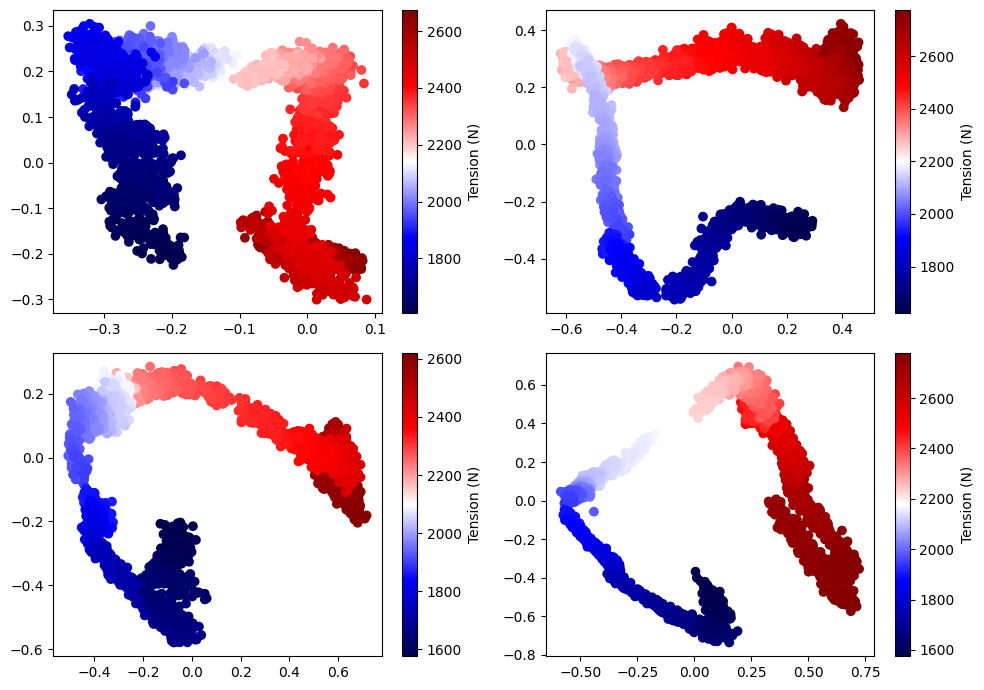

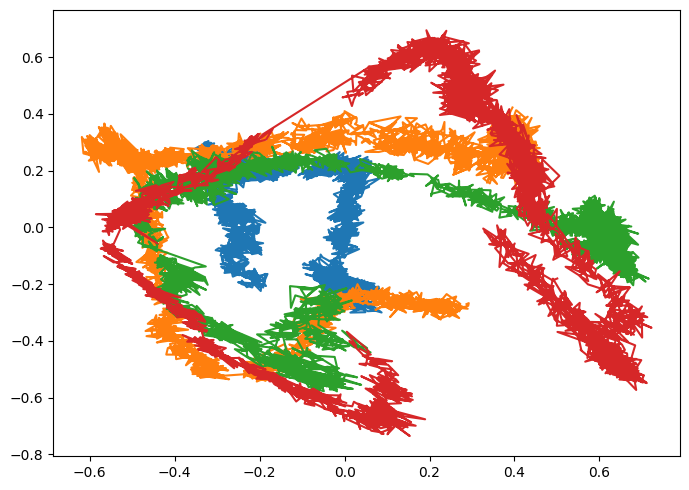

In [ ]:
models = {}
results = {}
data = {}

# Row-normalize
x = combined_features[features].to_numpy()
x = x / x.sum(axis=1, keepdims=True)

# Fit and transform
pipe = Pipeline([("scale", MinMaxScaler()), ("pca", PCA(n_components=2))])
pipe.fit(x)

plt.figure(figsize=(10, 7))
for i, cable in enumerate(CABLES):
    selected = combined_features.loc[combined_features["cable"]==cable].copy()
    x = selected[features].to_numpy()

    # Row-normalize
    x = x / x.sum(axis=1, keepdims=True)
    res = pipe.transform(x)

    # Plot
    plt.subplot(2,2,i+1)
    plt.scatter(res[:, 0], res[:, 1], c=selected["tension"], cmap="seismic")
    plt.colorbar(label="Tension (N)")
plt.tight_layout()

plt.figure(figsize=(7, 5))
markers = ["x", "o", "^", ">"]
for i, cable in enumerate(CABLES):
    selected = combined_features.loc[combined_features["cable"]==cable].copy()
    x = selected[features].to_numpy()

    # Row-normalize
    x = x / x.sum(axis=1, keepdims=True)
    res = pipe.transform(x)

    # Plot
    plt.scatter(res[:, 0], res[:, 1], c=selected["tension"], cmap="seismic", marker=markers[i], alpha=0.5)
plt.tight_layout()